# Panel b — camera tuning & JPEG export

Loads the attention-coloured `.pse` sessions built by
`scripts/build_panelb_sessions.py`, lets you orient each complex interactively
(headless PyMOL renders inline), and exports publication-DPI JPEGs.

**Workflow per complex**
1. `load('4QIL_C_A')` then `show()` to see the default `orient()` view.
2. Nudge with `cmd.turn('y', 30)` / `cmd.zoom(...)` / `cmd.move(...)` + `show()`.
3. When happy, `export('4QIL_C_A')` — writes the JPEG and records the view in
   `panel_b/views.json` so it is reproducible (`restore('4QIL_C_A')`).

Run from the repo root with the `encodersenv` kernel.

In [ ]:
import json
import sys
import tempfile
from pathlib import Path

# Repo-root bootstrap: makes `coral` importable without installing the package.
REPO_ROOT = Path.cwd().resolve()
while not (REPO_ROOT / "pyproject.toml").is_file() and REPO_ROOT != REPO_ROOT.parent:
    REPO_ROOT = REPO_ROOT.parent
sys.path.insert(0, str(REPO_ROOT / "src"))

import pymol2
from IPython.display import Image, display
from PIL import Image as PILImage
from coral import paths
from coral.paths import analysis_results

PANEL = analysis_results("contact_analysis") / "panel_b"
SESS, JPEG = PANEL / "sessions", PANEL / "jpeg"
VIEWS = PANEL / "views.json"

# One persistent headless PyMOL session for the whole notebook.
pm = pymol2.PyMOL()
pm.start()
cmd = pm.cmd
print("sessions:", [p.stem for p in sorted(SESS.glob("*.pse"))])

In [6]:
import pandas as pd

df = pd.read_csv(paths.PREDICTIONS_DIR / "pdb_predicted_interactions.csv")
positive = df.loc[df.prediction == 1]
positive

,RNA_id,Protein_id,PDB_id,RNA_seqs,Prot_seqs,prediction,interaction_probability,non_interaction_probability
5,1VBX|B,1VBX|A,1VBX|A,TGGCCGGCATGGTCCCAGCCTCCTCGCTGGCGCCGGCTGGGCAACA...,PETRPNHTIYINNLNEKIKKDELKKSLHAIFSRFGQILDILVSRSL...,1,0.999567,0.000433
6,1QRS|B,1QRS|A,1QRS|A,GGGGTATCGCCAAGCGGTAAGGCACCGGATTCTGATTCCGGCATTC...,TNFIRQIIDEDLASGKHTTVHTRFPPEPNGYLHIGHAKSICLNFGI...,1,0.680888,0.319112
7,2DU4|C,2DU4|A,2DU4|A,GCCAGGGTGGCAGAGGGGCTTTGCGGCGGACTGCAGATCCGCTTTA...,MKFDPQKYRELAEKDFEAAWKAGKEILAERSPNELYPRVGFSFGKE...,1,0.951462,0.048538
11,1U0B|A,1U0B|B,1U0B|B,GGCGCGTTAACAAAGCGGTTATGTAGCGGATTGCAAATCCGTCTAG...,MLKIFNTLTRQKEEFKPIHAGEVGMYVCGITVYDLCHIGHGRTFVA...,1,0.994155,0.005845
14,5YYN|B,5YYN|A,5YYN|A,GCGCTCGTAGCTCAATTGGATAGAGCATCAGAAGGTTAGGGGTTCG...,MNIQALLSEKVRQAMIAAGAPADCEPQVRQSAKVQFGDYQANGMMA...,1,0.956257,0.043743
...,...,...,...,...,...,...,...,...
715,5WTK|B,5WTK|A,5WTK|A,CACCCCAATATCGAAGGGGACTAAAACGACAATCAAACTC,GNLFGHKRWYEVRDKKDFKIKRKVKVKRNYDGNKYILNINENNNKE...,1,0.590178,0.409822
716,3ZLA|I,3ZLA|D,3ZLA|D,TTTTTTTTTTTTTTTTTTTTTTTTTTTTTTTTTTTTTTTTTTTT,GSMIELEFHDVTFDPEVAYANFKRVHTTGLSYDHIRIFYIKGREIK...,1,0.757412,0.242588
717,3ZLA|I,3ZLA|C,3ZLA|C,TTTTTTTTTTTTTTTTTTTTTTTTTTTTTTTTTTTTTTTTTTTT,GSMIELEFHDVATFDPEVAYANFKRVHTTGLSYDHIRIFYIKGREI...,1,0.713977,0.286023
718,1K8W|B,1K8W|A,1K8W|A,GGCAACGGTCGATCCCGTTGC,MDINGVLLLDKPQGMSSNDALQKVKRIYNANRAGHTGALDPLATGM...,1,0.974473,0.025527


In [10]:
positive.drop_duplicates(subset=["RNA_seqs", "Prot_seqs"])

,RNA_id,Protein_id,PDB_id,RNA_seqs,Prot_seqs,prediction,interaction_probability,non_interaction_probability
5,1VBX|B,1VBX|A,1VBX|A,TGGCCGGCATGGTCCCAGCCTCCTCGCTGGCGCCGGCTGGGCAACA...,PETRPNHTIYINNLNEKIKKDELKKSLHAIFSRFGQILDILVSRSL...,1,0.999567,0.000433
6,1QRS|B,1QRS|A,1QRS|A,GGGGTATCGCCAAGCGGTAAGGCACCGGATTCTGATTCCGGCATTC...,TNFIRQIIDEDLASGKHTTVHTRFPPEPNGYLHIGHAKSICLNFGI...,1,0.680888,0.319112
7,2DU4|C,2DU4|A,2DU4|A,GCCAGGGTGGCAGAGGGGCTTTGCGGCGGACTGCAGATCCGCTTTA...,MKFDPQKYRELAEKDFEAAWKAGKEILAERSPNELYPRVGFSFGKE...,1,0.951462,0.048538
11,1U0B|A,1U0B|B,1U0B|B,GGCGCGTTAACAAAGCGGTTATGTAGCGGATTGCAAATCCGTCTAG...,MLKIFNTLTRQKEEFKPIHAGEVGMYVCGITVYDLCHIGHGRTFVA...,1,0.994155,0.005845
14,5YYN|B,5YYN|A,5YYN|A,GCGCTCGTAGCTCAATTGGATAGAGCATCAGAAGGTTAGGGGTTCG...,MNIQALLSEKVRQAMIAAGAPADCEPQVRQSAKVQFGDYQANGMMA...,1,0.956257,0.043743
...,...,...,...,...,...,...,...,...
715,5WTK|B,5WTK|A,5WTK|A,CACCCCAATATCGAAGGGGACTAAAACGACAATCAAACTC,GNLFGHKRWYEVRDKKDFKIKRKVKVKRNYDGNKYILNINENNNKE...,1,0.590178,0.409822
716,3ZLA|I,3ZLA|D,3ZLA|D,TTTTTTTTTTTTTTTTTTTTTTTTTTTTTTTTTTTTTTTTTTTT,GSMIELEFHDVTFDPEVAYANFKRVHTTGLSYDHIRIFYIKGREIK...,1,0.757412,0.242588
717,3ZLA|I,3ZLA|C,3ZLA|C,TTTTTTTTTTTTTTTTTTTTTTTTTTTTTTTTTTTTTTTTTTTT,GSMIELEFHDVATFDPEVAYANFKRVHTTGLSYDHIRIFYIKGREI...,1,0.713977,0.286023
718,1K8W|B,1K8W|A,1K8W|A,GGCAACGGTCGATCCCGTTGC,MDINGVLLLDKPQGMSSNDALQKVKRIYNANRAGHTGALDPLATGM...,1,0.974473,0.025527


In [2]:
def load(cid: str) -> None:
    """Load a panel-b session (cid like '4QIL_C_A') and orient it."""
    cmd.reinitialize()
    cmd.load(str(SESS / f"{cid}.pse"))
    cmd.orient()


def show(w: int = 700, h: int = 700) -> None:
    """Ray-trace the current view and display it inline (fast preview size)."""
    tmp = tempfile.NamedTemporaryFile(suffix=".png", delete=False).name
    cmd.png(tmp, width=w, height=h, dpi=100, ray=1)
    display(Image(filename=tmp))


def export(cid: str, w: int = 2400, h: int = 2400, dpi: int = 400) -> Path:
    """Render the current view to a high-DPI JPEG and record the camera.

    PyMOL's png() only writes PNG, so we render PNG then convert with Pillow.
    """
    JPEG.mkdir(parents=True, exist_ok=True)
    out = JPEG / f"{cid}.jpeg"
    tmp = tempfile.NamedTemporaryFile(suffix=".png", delete=False).name
    cmd.set("ray_opaque_background", 1)
    cmd.png(tmp, width=w, height=h, dpi=dpi, ray=1)
    PILImage.open(tmp).convert("RGB").save(out, quality=95)
    views = json.loads(VIEWS.read_text()) if VIEWS.exists() else {}
    views[cid] = list(cmd.get_view())
    VIEWS.write_text(json.dumps(views, indent=2))
    print("saved", out)
    return out


def restore(cid: str) -> None:
    """Re-apply a previously saved camera for `cid`."""
    views = json.loads(VIEWS.read_text())
    cmd.set_view(views[cid])

## 4QIL|C_A — Roquin ROQ / CDE hairpin

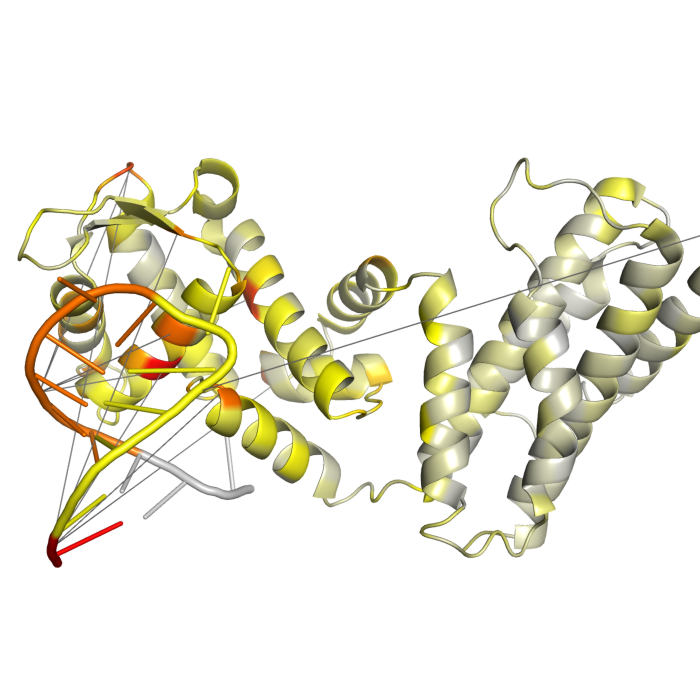

In [6]:
load("4QIL_C_A")
show()

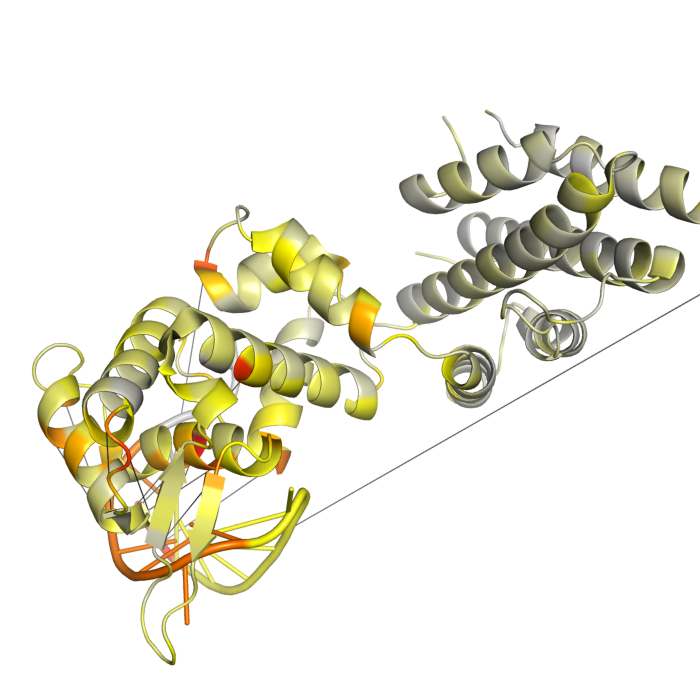

: 

In [ ]:
# --- Nudge the camera, re-run this cell until the angle looks good. ---
#cmd.turn("y", 30)   # rotate about vertical axis (degrees)
cmd.turn("x", 90) # tilt
# cmd.turn("z", 10) # roll
# cmd.zoom("all", buffer=5)
# cmd.move("z", -10)  # dolly toward/away
show()

In [ ]:
# Print the current camera (paste into views.json or a script to reproduce).
print(cmd.get_view())

In [ ]:
export("4QIL_C_A")

## 2NUE|C_A — RNase III / dsRNA duplex

In [ ]:
load("2NUE_C_A")
show()

In [ ]:
cmd.turn("y", 30)
show()

In [ ]:
export("2NUE_C_A")

## 2UWM|C_A — SelB / SECIS hairpin

In [ ]:
load("2UWM_C_A")
show()

In [ ]:
cmd.turn("y", 30)
show()

In [ ]:
export("2UWM_C_A")

### Tips
- `restore('4QIL_C_A')` re-applies a saved camera (after `load`).
- Lines too dense? Re-run the script with a smaller threshold, e.g.
  `python analyses/contact_analysis/scripts/build_panelb_sessions.py --top-percent 1`,
  then reload the session here.
- `cmd.set('cartoon_transparency', 0.3)` can de-emphasise the protein cartoon.